# Week 1 - Day 5
## Python & Data Engineering
### Task 2: Exploratory Data Analysis (EDA)

Objective:
To analyse the cleaned employee dataset using summary statistics,
groupby, correlation, business questions, merging and pivot tables.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("clean_data.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1470, 35)

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   Busin

In [4]:
numeric_columns = df.select_dtypes(include=np.number).columns

summary_statistics = df[numeric_columns].agg(
    ['mean', 'median', 'min', 'max', 'std']
)

summary_statistics

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
median,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136


In [5]:
department_analysis = df.groupby('Department', observed=True).agg(
    Average_Age=('Age', 'mean'),
    Average_MonthlyIncome=('MonthlyIncome', 'mean'),
    Average_DailyRate=('DailyRate', 'mean'),
    Employee_Count=('Age', 'count')
)

department_analysis

,Average_Age,Average_MonthlyIncome,Average_DailyRate,Employee_Count
Department,,,,
Human Resources,37.809524,6654.507937,751.539683,63
Research & Development,37.042664,6281.252862,806.851197,961
Sales,36.542601,6959.172646,800.275785,446


In [6]:
jobrole_analysis = df.groupby('JobRole', observed=True).agg(
    Average_Age=('Age', 'mean'),
    Average_MonthlyIncome=('MonthlyIncome', 'mean'),
    Average_DailyRate=('DailyRate', 'mean'),
    Employee_Count=('Age', 'count')
)

jobrole_analysis

,Average_Age,Average_MonthlyIncome,Average_DailyRate,Employee_Count
JobRole,,,,
Healthcare Representative,39.809160,7528.763359,854.251908,131
Human Resources,35.500000,4235.750000,757.923077,52
Laboratory Technician,34.096525,3237.169884,796.617761,259
Manager,46.764706,17181.676471,782.950980,102
Manufacturing Director,38.296552,7295.137931,796.020690,145
Research Director,44.000000,16033.550000,802.450000,80
Research Scientist,34.236301,3239.972603,800.359589,292
Sales Executive,36.889571,6924.279141,802.098160,326
Sales Representative,30.361446,2626.000000,811.349398,83


In [7]:
gender_analysis = df.groupby('Gender', observed=True).agg(
    Average_Age=('Age', 'mean'),
    Average_MonthlyIncome=('MonthlyIncome', 'mean'),
    Employee_Count=('Age', 'count')
)

gender_analysis

,Average_Age,Average_MonthlyIncome,Employee_Count
Gender,,,
Female,37.329932,6686.566327,588
Male,36.653061,6380.507937,882


In [8]:
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

correlation_matrix

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,0.010661,-0.001686,0.208034,NaN,-0.010145,0.010146,0.024287,0.029820,0.509604,...,0.053535,NaN,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
DailyRate,0.010661,1.000000,-0.004985,-0.016806,NaN,-0.050990,0.018355,0.023381,0.046135,0.002966,...,0.007846,NaN,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,-0.004985,1.000000,0.021042,NaN,0.032916,-0.016075,0.031131,0.008783,0.005303,...,0.006557,NaN,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.016806,0.021042,1.000000,NaN,0.042070,-0.027128,0.016775,0.042438,0.101589,...,-0.009118,NaN,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EmployeeCount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeNumber,-0.010145,-0.050990,0.032916,0.042070,NaN,1.000000,0.017621,0.035179,-0.006888,-0.018519,...,-0.069861,NaN,0.062227,-0.014365,0.023603,0.010309,-0.011240,-0.008416,-0.009019,-0.009197
EnvironmentSatisfaction,0.010146,0.018355,-0.016075,-0.027128,NaN,0.017621,1.000000,-0.049857,-0.008278,0.001212,...,0.007665,NaN,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,0.023381,0.031131,0.016775,NaN,0.035179,-0.049857,1.000000,0.042861,-0.027853,...,0.001330,NaN,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,0.046135,0.008783,0.042438,NaN,-0.006888,-0.008278,0.042861,1.000000,-0.012630,...,0.034297,NaN,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,0.002966,0.005303,0.101589,NaN,-0.018519,0.001212,-0.027853,-0.012630,1.000000,...,0.021642,NaN,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281


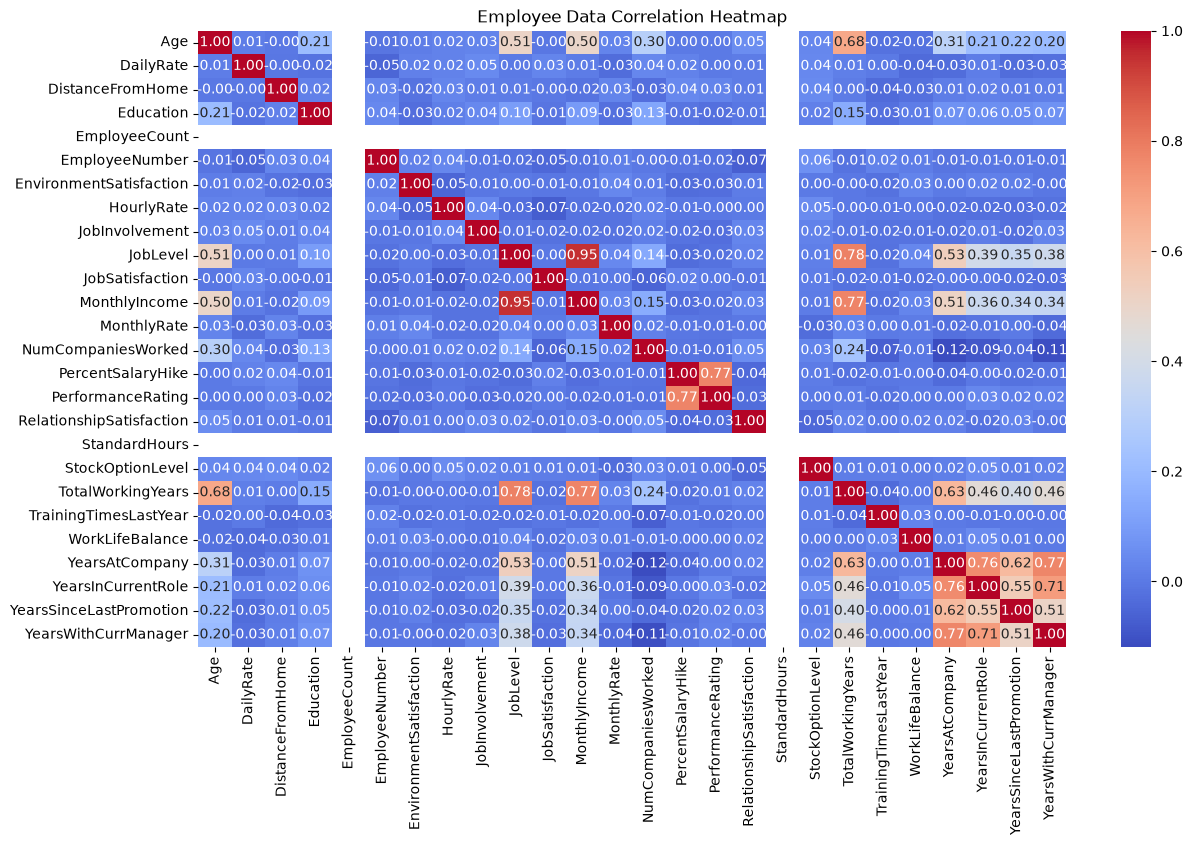

In [9]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=True,
    fmt='.2f'
)

plt.title("Employee Data Correlation Heatmap")
plt.show()

In [10]:
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack()

top_3_correlations = corr_pairs.reindex(
    corr_pairs.abs().sort_values(ascending=False).index
).head(3)

print("Top 3 Correlations:")
print(top_3_correlations)

Top 3 Correlations:
JobLevel           MonthlyIncome        0.950300
                   TotalWorkingYears    0.782208
PercentSalaryHike  PerformanceRating    0.773550
dtype: float64


## Business Questions

1. Which department has the highest average monthly income?
2. Which job role has the highest number of employees?
3. What is the average monthly income of employees?
4. Which department has the highest number of employees?
5. What is the average age of employees?

In [11]:
avg_income = df.groupby('Department')['MonthlyIncome'].mean()

print("Department with Highest Average Monthly Income:")
print(avg_income.idxmax())

print("Average Monthly Income:")
print(round(avg_income.max(), 2))

Department with Highest Average Monthly Income:
Sales
Average Monthly Income:
6959.17


In [12]:
job_counts = df['JobRole'].value_counts()

print("Job Role with Highest Employees:")
print(job_counts.idxmax())

print("Number of Employees:")
print(job_counts.max())

Job Role with Highest Employees:
Sales Executive
Number of Employees:
326


In [13]:
average_income = df['MonthlyIncome'].mean()

print("Average Monthly Income:")
print(round(average_income, 2))

Average Monthly Income:
6502.93


In [14]:
department_counts = df['Department'].value_counts()

print("Department with Highest Employees:")
print(department_counts.idxmax())

print("Number of Employees:")
print(department_counts.max())

Department with Highest Employees:
Research & Development
Number of Employees:
961


In [15]:
average_age = df['Age'].mean()

print("Average Employee Age:")
print(round(average_age, 2))

Average Employee Age:
36.92


In [16]:
department_budget = pd.DataFrame({
    'Department': [
        'Human Resources',
        'Research & Development',
        'Sales'
    ],
    'Budget': [
        500000,
        1000000,
        850000
    ]
})

department_budget

,Department,Budget
0,Human Resources,500000
1,Research & Development,1000000
2,Sales,850000


In [17]:
merged_df = pd.merge(
    df,
    department_budget,
    on='Department',
    how='left'
)

merged_df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Budget
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,80,0,8,0,1,6,4,0,5,850000
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,80,1,10,3,3,10,7,1,7,1000000
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,80,0,7,3,3,0,0,0,0,1000000
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,80,0,8,3,3,8,7,3,0,1000000
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,80,1,6,3,3,2,2,2,2,1000000


In [18]:
pivot_table = pd.pivot_table(
    df,
    index='Department',
    columns='JobRole',
    values='Age',
    aggfunc='count',
    fill_value=0,
    observed=False
)

pivot_table

JobRole,Healthcare Representative,Human Resources,Laboratory Technician,Manager,Manufacturing Director,Research Director,Research Scientist,Sales Executive,Sales Representative
Department,,,,,,,,,
Human Resources,0,52,0,11,0,0,0,0,0
Research & Development,131,0,259,54,145,80,292,0,0
Sales,0,0,0,37,0,0,0,326,83


## Conclusion

Exploratory Data Analysis was completed successfully.

The following operations were performed:

1. Calculated summary statistics.
2. Compared departments using groupby().agg().
3. Compared job roles and genders.
4. Calculated correlation between numerical columns.
5. Identified the top 3 correlation relationships.
6. Answered 5 business questions using numerical results.
7. Created a department budget table.
8. Merged datasets using pd.merge().
9. Created a pivot table using pd.pivot_table().

EDA helped identify employee patterns and generate
useful business insights.